In [1]:
import matplotlib.pyplot as plt
from astropy.io import fits
import os
import matplotlib as mpl
import pandas as pd
import math as math
from astropy import units as u
import numpy as np
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks
from pyspeckit.spectrum.units import SpectroscopicAxis
import pybaselines
import aplpy
import itertools
from specutils.manipulation import FluxConservingResampler
from specutils import Spectrum1D
from pybaselines.polynomial import modpoly
from sqlalchemy import create_engine, inspect, MetaData, Table, text
import mysql.connector
import warnings
from astropy.utils.exceptions import AstropyWarning
from striprtf.striprtf import rtf_to_text

In [2]:
mydb = mysql.connector.connect(
  host="127.0.0.1",
  user="root",
 # passwd=" ",      #<----
  database = "HiGAL_250_280"   #<----
)

In [7]:
# This is the original template sent by Ivana

def gaus(x,a,mu,sigma):
	return a*np.exp(-(x-mu)**2/(2*sigma**2))

def gaus3(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2))

def gaus2(x,a1,mu1,sigma1,a2,mu2,sigma2):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2))

def gaus4(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2))

def gaus5(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2))

def gaus6(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2))

def gaus7(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6, a7,mu7,sigma7):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2)) +a7*np.exp(-(x-mu7)**2/(2*sigma7**2))

def create_db_connection():
    # Use SQLAlchemy for better connection management
    db_url = "mysql+pymysql://root@127.0.0.1:3306/HiGAL_250_280"
    engine = create_engine(db_url)
    return engine

def execute_query(engine, query):
    try:
        with engine.connect() as connection:
            connection.execute(query)
            connection.commit()
    except Exception as e:
        print(f"An error occurred: {e}")

def noise_calc(y,file):

    fig, ax = plt.subplots()
    y=np.array(y)
    #y = y[~np.isnan(y)]
    print(np.shape(y), y)
    y_negative = y[np.where(y <  0)]
    y_new = np.concatenate((y_negative,-1*y_negative),axis=None)
    y_mean = np.nanmean(y_new)
    y_stdev = np.nanstd(y_new)

    y_noise_array =  y[np.where(y <  abs(y_stdev*5))]

    n, bin_edges, p = plt.hist(y_noise_array,bins = 20, alpha=0.5,color='rosybrown',align='mid' )

    gauss_bins = bin_edges[:-1]+((bin_edges[1]-bin_edges[0])/2.)

    #print(np.mean(y_noise_array), np.max(y_noise_array))
    popt, pcov = curve_fit(gaus,gauss_bins, n, p0=[np.nanmax(n),np.nanmean(y_noise_array),np.nanstd(y_noise_array)])
    #print(popt)

    guass_fit_bins = (np.array(range(-90,100,1))-5)/200.
    ax.plot(guass_fit_bins,gaus(guass_fit_bins,*popt),'r')
    plt.axvline(x=3*abs(popt[2]), color='grey', linestyle=':')
    ax.set_xlabel('T$_{mb}$ [K]')
    ax.set_ylabel('Number of Channels')
    ax.set_title(f"{file}")
    noise_string = r'RMS Noise ($\sigma$)= '+str(round(abs(popt[2]),2)) + ' K'
    mean_string = r'Mean Offset= '+str(round(abs(popt[1]),2)) + ' K'
    plt.text(0.05, 0.9, noise_string, transform=ax.transAxes)
    plt.text(0.05, 0.8, mean_string, transform=ax.transAxes)

    y = [n-popt[1] for n in y]
    y_noise_array = [n-popt[1] for n in y_noise_array]
    n, bins, p = plt.hist(y_noise_array,bins=bin_edges, alpha=0.25,color='green',align='mid' )
    ###plt.savefig(output_dir+f'{file}_noise.png')
    #plt.show()    #<--------------------- make shure this is commented when running big loop
    plt.close()

    print('')
    print('-----Noise parameter is calculated -----')
    print('')

    return(1*abs(popt[2]), y)

def baseline_correction(flux, x):

    #fig, ax = plt.subplots()
    #ax.step(x, flux, color = '#539ecd')

    smooth_y = uniform_filter1d(flux, 9)
    smooth_x=x

    #baseline_fitter = Baseline(x_data=smooth_x)
    #bkg_1 = baseline_fitter.imodpoly(smooth_y, poly_order=5)[0]

    bkg_1, f = modpoly(smooth_y, poly_order=5)

    flux_blsub = [flux[num]-bkg_1[num] for num in range(len(flux))]#corecting the flux value by subtracting baseline

    fig, ax = plt.subplots()
    ax.step(x,flux, color = '#539ecd')
    ax.step(x,flux_blsub, color = 'red')
    ax.step(x, np.array(bkg_1), color = 'lime')

    #plt.title(each)
    plt.xlim(-50,150)
    plt.ylabel(r'T$_a^*$ (K)')
    plt.xlabel(r'Velocity (km s$^{-1}$)')
    #print(path_to_output+each+'_data_raw.png')
    #plt.savefig(path_to_output+each+'_data_raw.png')
    #plt.show()    #<--------------------- make shure this is commented when running big loop
    #plt.close()

    #ax.step(smooth_x, smooth_y, color = 'orange')
    #ax.step(smooth_x, bkg_1, color = 'blue')

    #plt.show()    #<--------------------- make shure this is commented when running big loop
    print('')
    print('-----Baseline correction has been executed-----')
    print('')

    return(flux_blsub,x,bkg_1)

def change_v_res(Vlsr,Tmb,sm_idx):
    print(len(Vlsr), len(Tmb))
    print(Vlsr[:10])
    new_res = (Vlsr[1]-Vlsr[0])*sm_idx
    new_Vlsr = np.arange(min(Vlsr),max(Vlsr),new_res)
    print(len(new_Vlsr), new_Vlsr[:10])

    print(Tmb[:10])
    new_Tmb = list(itertools.chain.from_iterable([i]*sm_idx for i in [sum(Tmb[i:i+sm_idx])/sm_idx for i in range(0,len(Tmb),sm_idx)]))
    new_Tmb2 = new_Tmb[::sm_idx]
    print(len(new_Tmb2), new_Tmb[:10])
    return (new_Vlsr, new_Tmb2)

def smooth_1d_spectrum(Vlsr,Tmb,sm_idx):
    '''
    smooth the 1d spectra to sm_idx*resolution of 1d spectra
    for example, if want to reduce the velocity resolution from 0.25km/s to 0.5 km/s, set sm_idx=2
    '''

    Vlsr = np.array(Vlsr)*u.km/u.s
    Tmb  = np.array(Tmb)*u.K
    input_spec = Spectrum1D(spectral_axis=Vlsr, flux=Tmb)
    deltaVlsr =Vlsr[1]-Vlsr[0]
    print('the orignal spectral resolution',deltaVlsr)
    new_resolution = sm_idx*deltaVlsr.value
    print('the new spectral resolution',new_resolution)
    new_disp_grid = np.arange(min(Vlsr).value,max(Vlsr).value,new_resolution)*u.km/u.s
    print('channels of original spectral and new spectra',len(Vlsr),len(new_disp_grid))
    fluxcon = FluxConservingResampler(extrapolation_treatment='zero_fill')
    new_spec_fluxcon = fluxcon(input_spec, new_disp_grid)
    #outspec = Table([new_spec_fluxcon.spectral_axis,new_spec_fluxcon.flux],names=['Vlsr','Tmb'])
    ##you can save the results
    #ascii.write(outspec,infile[0:-4]+'_smooth_'+str(sm_idx)+infile[-4:],format='commented_header',overwrite=True)

    print('')
    print('-----Velocity resolution is reduced by a factor of 2 -----')
    print('')

    return new_spec_fluxcon.spectral_axis, np.nan_to_num(new_spec_fluxcon.flux,copy=True, nan=0.0)

def smooth(Tmb,window_len,window):
    """smooth the data using a window with requested size.

    This method is based on the convolution of a scaled window with the signal.
    The signal is prepared by introducing reflected copies of the signal
    (with the window size) in both ends so that transient parts are minimized
    in the begining and end part of the output signal.

    input:
        x: the input signal
        window_len: the dimension of the smoothing window; should be an odd integer
        window: the type of window from 'flat', 'hanning', 'hamming', 'bartlett', 'blackman'
            flat window will produce a moving average smoothing.

    output:
        the smoothed signal

    example:

    t=linspace(-2,2,0.1)
    x=sin(t)+randn(len(t))*0.1
    y=smooth(x)

    see also:

    numpy.hanning, numpy.hamming, numpy.bartlett, numpy.blackman, numpy.convolve
    scipy.signal.lfilter

    TODO: the window parameter could be the window itself if an array instead of a string
    NOTE: length(output) != length(input), to correct this: return y[(window_len/2-1):-(window_len/2)] instead of just y.
    """

    #print(x.ndim)
    #print('length x',len(Tmb))
    #x=np.array(Tmb)
    #print('Tmb', Tmb[0:5])



    s=np.r_[Tmb[window_len-1:0:-1],Tmb,Tmb[-2:-window_len-1:-1]]

    #print('first part ', x[window_len-1:0:-1])
    #print('end part ',x[-2:-window_len-1:-1])

    #print('length first part',len( x[window_len-1:0:-1]))
   # print('length last part',len(x[-2:-window_len-1:-1]))
   # print('s ',s[0:8])
    #print(len(x[0:5]))

    #print('length s',len(s))
    if window == 'flat': #moving average
        w=np.ones(window_len,'d')
    else:
        w=eval('np.'+window+'(window_len)')

    y=np.convolve(w/w.sum(),s,mode='valid')[window_len-3:-window_len+3]
    #x= vlsr[window_len-2:-window_len+2]
    #print('length y',len(y))
    #print(y)
    return  y

def fit_parameters_to_table(popt, pcov):
    #print(pcov)
    #print(popt)
    perr = np.sqrt(np.diag(pcov))

    #print('peak =',popt[0])
    #print('vlsr =',popt[1])
    #print ('width = ', popt[2])

    ppp=0
    lll = 0


    while ppp <= len(popt)-1:
        lll=lll+1

        print('integer ', ppp)
        print('num elements', len(popt))
        print('peak =',popt[ppp])
        print('vlsr =',popt[ppp+1])
        print ('width = ', popt[ppp+2])
        print('integrated flux ',  popt[ppp]*popt[ppp+2]*2.355, noise[iii]*9)

        if (popt[ppp] > noise[iii]*3. or popt[ppp]*popt[ppp+2]*2.355 > noise[iii]*9) and popt[ppp+2] > 0.15  :

            #print('perr[0]',str(round(chi2/float(NDF),4)))
            integrated_intensity_reference = popt[ppp+0]*popt[ppp+2]

            if math.isinf(perr[ppp]):
                perr[ppp] = -999

            if math.isinf(perr[ppp+1]):
                perr[ppp+1] = -999

            if math.isinf(perr[ppp+2]):
                perr[ppp+2] = -999


            ###query = "INSERT INTO table_name (higal_name, component_index,  Temp, Temp_error, vlsr, vlsr_error, dvlsr, dvlsr_error,integrated_intensity,intensity_ratio, input_time) VALUES ('"+each+"','"+str(lll)+ "','"+str(round((popt[ppp]),4)) +"', '" + str(round(abs(perr[ppp]),5)) +"', '"+str(round((popt[ppp+1]),4)) +"','" + str(round(abs(perr[ppp+1]),5)) + "','" +str(round((popt[ppp+2]),4)) + "','" + str(round(abs(perr[ppp+2]),5)) +"', '"+str(round(popt[ppp+0]*popt[ppp+2],4))+"','"+str(round(popt[ppp+0]*popt[ppp+2]/integrated_intensity_reference,4))+"', now()) "
            ###print(query)
            ###execute_query(mydb, query)
            #print('gauss fit ',np.array(xaxis))

            ppp= ppp+3
            
def plot_spectra(spectra_dir, engine):
    # List all FITS files in the spectra directory
    spectra_files = [f for f in os.listdir(spectra_dir) if f.endswith('spec.fits') and f.startswith('12CO')]
    query = 'SELECT gal_long, gal_lat, higal_name, VLSR FROM higal_mopra_co'
    df = pd.read_sql(query, con=engine)

    # Loop through the list of files
    for spectra_file in spectra_files:
        with fits.open(os.path.join(spectra_dir, spectra_file)) as hdul:
            Tmb = hdul[0].data
            hd = hdul[0].header

        refc = hd['CRPIX3']
        velo = hd['CRVAL3']
        dv = hd['CDELT3']

        # Define the velocity axis
        Vlsr = np.divide(np.add(np.multiply(np.subtract(np.arange(1, hd['NAXIS1'] + 1), refc), dv), velo), 1000)
        xaxis = np.array(SpectroscopicAxis(Vlsr, refX=hd['RESTFREQ'] * u.Hz, velocity_convention='radio'))
        xaxis = xaxis[674:-1658]
        Tmb = Tmb[674:-1658]

        # Change velocity resolution
        xaxis, Tmb = change_v_res(xaxis, Tmb, 4)

        # Smooth the data
        Tmb = smooth(Tmb, 5, 'hanning')

        # Baseline correction and noise calculation
        noise, y = noise_calc(Tmb, spectra_file)
        
    # Figures out how many Gaussians to fit:
    
        peak_channel = 100+np.argmax([y[100:-100]])
        peak_vlsr = xaxis[peak_channel]
        print(peak_vlsr)
        #print(np.where(y[200:-400] >  noise*3.5))
        channels_above_noise = 100+np.where(y[100:-100] >  noise*3.5)[0]
        gaussian_flag = channels_above_noise.size
        print('Gauss flag',gaussian_flag)

        peaks, prop= find_peaks(y, height = noise*3.5, width = 3)
        component_index = len(peaks)
        
        if (component_index > 0 and component_index < 8):
            width_guess = .5
            if component_index == 1:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess]
                gauss_fn =   gaus
            if component_index == 2:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess]
                gauss_fn =   gaus2
            if component_index == 3:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess]
                gauss_fn =   gaus3
            if component_index == 4:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess]
                gauss_fn =   gaus4
            if component_index == 5:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess]
                gauss_fn =   gaus5
            if component_index == 6:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess,Tmb[peaks[5]], xaxis[peaks[5]], width_guess]
                gauss_fn =   gaus6
            if component_index == 7:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess,Tmb[peaks[5]], xaxis[peaks[5]], width_guess,Tmb[peaks[6]], xaxis[peaks[6]], width_guess]
                gauss_fn =   gaus7

        y = np.nan_to_num(y)
        weight=0.0*y + noise
        
        ### STARTING FIGURE ###
        
        fig, ax = plt.subplots()
        plt.step(xaxis,y, color = '#539ecd')
        if (component_index > 0 and component_index < 8):
            popt, pcov = curve_fit(gauss_fn,xaxis, y,guesses, sigma=weight, absolute_sigma=True)
            plt.plot(xaxis,gauss_fn(xaxis,*popt),'r')
        #fit_parameters_to_table(popt, pcov)    #to output parameters to SQL table
        higal_v = df[df['higal_name'] == spectra_file[5:-10]]['VLSR'].iloc[0]
        noise_string = r'RMS Noise ($\sigma$)= '+str(round(abs(noise),2)) + ' K' ###noise[iii]
        plt.text(0.05, 0.85, noise_string, transform=ax.transAxes)
        plt.text(0.05, 0.8, f'HiGAL Vlsr={higal_v} km/s', transform=ax.transAxes)
        ax.axvline(higal_v, color='pink', alpha = .8, zorder=0)
        ax.set_xlim([-25, 150])
        plt.ylabel(r'T$_{\rm mb}$ (K)')
        plt.xlabel(r'Velocity (km s$^{-1}$)')
        plt.title(f'{spectra_file[:-10]}')
        plt.savefig(f'{output_dir}/{spectra_file[:-10]}.png')
        #plt.show()    #<--------------------- make sure this is commented when running big loop


In [4]:
# This is the modidfied one I use

from scipy.optimize import curve_fit
from astropy import units as u
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Placeholder Gaussian fitting functions
def gaus(x,a,mu,sigma):
	return a*np.exp(-(x-mu)**2/(2*sigma**2))

def gaus3(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2))

def gaus2(x,a1,mu1,sigma1,a2,mu2,sigma2):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2))

def gaus4(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2))

def gaus5(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2))

def gaus6(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2))

def gaus7(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6, a7,mu7,sigma7):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2)) +a7*np.exp(-(x-mu7)**2/(2*sigma7**2))


def plot_spectra(engine, spectra_dir, output_dir, vmin=-200, vmax=200):
    print("Starting the plot_spectra function.")
    
    # List all FITS files in the directory
    spectra_files = [f for f in os.listdir(spectra_dir) if f.endswith('spec.fits') and f.startswith('12CO') or f.startswith('13CO') or f.startswith('C18O')]
    print(f"Number of FITS files found: {len(spectra_files)}")
    
    # Read in the database information
    df = pd.read_sql_query('SELECT gal_long, gal_lat, higal_name, VLSR FROM higal_mopra_co', con=engine)
    print(f"Number of records fetched from the table: {len(df)}")

    for spectra_file in spectra_files:
        print(f"\nProcessing file: {spectra_file}")
        with fits.open(os.path.join(spectra_dir, spectra_file)) as hdul:
            Tmb = hdul[0].data
            hd = hdul[0].header

        refc = hd['CRPIX3']
        velo = hd['CRVAL3']
        dv = hd['CDELT3']

        # Create the velocity axis
        Vlsr = (velo + (np.arange(1, hd['NAXIS1'] + 1) - refc) * dv) / 1000.0  # Convert to km/s
        #xaxis = Vlsr * u.km / u.s  # Create Quantity object for velocity
        xaxis=Vlsr

        # Trim data (adjust indices as per your data)
        #xaxis = xaxis[int(refc):int(lowlim)]  # Try CRPIX3-NAXIS3
        if vmin is not None and vmax is not None:
            valid_indices = (xaxis >= vmin) & (xaxis <= vmax)
            xaxis = xaxis[valid_indices]
            Tmb = Tmb[valid_indices]        #Tmb = Tmb[5431:-1658]
        

        # Smooth the data to reduce noise
        Tmb = smooth(Tmb, 5, 'hanning')

        # Noise calculation
        noise, y = noise_calc(Tmb, spectra_file)
        
        # Find the peak channel
        peak_channel = 100 + np.argmax([y[100:-100]])
        peak_vlsr = xaxis[peak_channel]
        print(f"Peak VLSR: {peak_vlsr}")
        
        # Identify channels above noise threshold
        channels_above_noise = 100 + np.where(y[100:-100] > noise * 3.5)[0]
        gaussian_flag = channels_above_noise.size
        print(f"Gauss flag: {gaussian_flag}")

        # Identify peaks and count the components
        peaks, _ = find_peaks(y, height=noise * 3.5, width=3)
        component_index = len(peaks)
        print(f"Number of Gaussian components: {component_index}")
        
        # Initialize gauss_fn to None before assigning it to ensure it's always defined
        gauss_fn = None

        # Set the appropriate Gaussian function and initial guesses based on the number of components
        width_guess = 0.5
        if component_index > 0 and component_index < 8:
            if component_index == 1:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess]
                gauss_fn = gaus
            elif component_index == 2:
                guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess]
                gauss_fn = gaus2
            # Continue for other cases up to gaus7...

        # Perform Gaussian fitting only if a suitable function is defined
        if gauss_fn is not None:
            try:
                # Convert xaxis and y to numerical values (without units)
                #xaxis_values = xaxis.value  # Strip units from the velocity axis
                weight = np.zeros_like(y) + noise
                popt, pcov = curve_fit(gauss_fn, xaxis, y, guesses, sigma=weight, absolute_sigma=True)

                # Plot the results
                fig, ax = plt.subplots()
                plt.step(xaxis, y, color='#539ecd')  # Use xaxis_values instead of xaxis
                plt.plot(xaxis, gauss_fn(xaxis, *popt), 'r')  # Use xaxis_values here too
                higal_v = df[df['higal_name'] == spectra_file[5:-10]]['VLSR'].iloc[0]
                noise_string = r'RMS Noise ($\sigma$)= '+str(round(abs(noise),2)) + ' K' ###noise[iii]
                plt.text(0.05, 0.85, noise_string, transform=ax.transAxes)
                plt.text(0.05, 0.8, f'HiGAL Vlsr={higal_v} km/s', transform=ax.transAxes)
                ax.axvline(higal_v, color='pink', alpha = .8, zorder=0)
                ax.set_xlim([-25, 150])
                plt.ylabel(r'T$_{\rm mb}$ (K)')
                plt.xlabel(r'Velocity (km s$^{-1}$)')
                plt.title(f'{spectra_file[:-10]}')
                plt.savefig(f'{output_dir}/{spectra_file[:-10]}.png')
            except Exception as e:
                print(f"Failed to fit Gaussian for {spectra_file}: {e}")
        else:
            print(f"No Gaussian components detected or too many components for {spectra_file}. Skipping fitting.")


In [3]:
# This is a slight modification of the second one that displays fit parameters on the plots

from scipy.optimize import curve_fit
from astropy import units as u
import os
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def gaus(x,a,mu,sigma):
	return a*np.exp(-(x-mu)**2/(2*sigma**2))

def gaus3(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2))

def gaus2(x,a1,mu1,sigma1,a2,mu2,sigma2):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2))

def gaus4(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4):
	return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2))

def gaus5(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2))

def gaus6(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2))

def gaus7(x,a1,mu1,sigma1,a2,mu2,sigma2,a3,mu3,sigma3, a4,mu4,sigma4, a5,mu5,sigma5, a6,mu6,sigma6, a7,mu7,sigma7):
    return a1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + a2*np.exp(-(x-mu2)**2/(2*sigma2**2)) +a3*np.exp(-(x-mu3)**2/(2*sigma3**2)) +a4*np.exp(-(x-mu4)**2/(2*sigma4**2)) +a5*np.exp(-(x-mu5)**2/(2*sigma5**2)) +a6*np.exp(-(x-mu6)**2/(2*sigma6**2)) +a7*np.exp(-(x-mu7)**2/(2*sigma7**2))


def plot_spectra(engine, spectra_dir, output_dir, successful_fits_dir, output_file, vmin=-120, vmax=120):
    print("Starting the plot_spectra function.")
    
    # List all FITS files in the directory
    spectra_files = [f for f in os.listdir(spectra_dir) if f.endswith('spec.fits') and (f.startswith('12CO') or f.startswith('13CO') or f.startswith('C18O'))]
    print(f"Number of FITS files found: {len(spectra_files)}")
    
    # Read in the database information
    df = pd.read_sql_query('SELECT gal_long, gal_lat, higal_name, VLSR FROM higal_mopra_co', con=engine)
    print(f"Number of records fetched from the table: {len(df)}")

    with open(output_file, 'w') as f:
        # Write the header line for the output file
        f.write("Number\tObject Name\tMolecule Type\tNum Components\tAmplitudes (K)\tMean Velocities (km/s)\tWidths (km/s)\n")        
        number=1
        for spectra_file in spectra_files:
            print(f"\nProcessing file: {spectra_file}")
            with fits.open(os.path.join(spectra_dir, spectra_file)) as hdul:
                Tmb = hdul[0].data
                hd = hdul[0].header

            refc = hd['CRPIX3']
            velo = hd['CRVAL3']
            dv = hd['CDELT3']

        # Create the velocity axis
            Vlsr = (velo + (np.arange(1, hd['NAXIS1'] + 1) - refc) * dv) / 1000.0  # Convert to km/s
            xaxis = Vlsr

        # Trim data (adjust indices as per your data)
            if vmin is not None and vmax is not None:
                valid_indices = (xaxis >= vmin) & (xaxis <= vmax)
                xaxis = xaxis[valid_indices]
                Tmb = Tmb[valid_indices]
        
        # Smooth the data to reduce noise
            Tmb = smooth(Tmb, 5, 'hanning')

        # Noise calculation
            noise, y = noise_calc(Tmb, spectra_file)
        
        # Find the peak channel
            peak_channel = 100 + np.argmax([y[100:-100]])
            peak_vlsr = xaxis[peak_channel]
            print(f"Peak VLSR: {peak_vlsr}")
        
        # Identify channels above noise threshold
            channels_above_noise = 100 + np.where(y[100:-100] > noise * 3.5)[0]
            gaussian_flag = channels_above_noise.size
            print(f"Gauss flag: {gaussian_flag}")


            peaks, prop= find_peaks(y, height = noise*3.5, width = 3)
            component_index = len(peaks)

        # Initialize gauss_fn to None before assigning it to ensure it's always defined
            gauss_fn = None
        
            if (component_index > 0 and component_index < 4):
                width_guess = .5
                if component_index == 1:
                    guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess]
                    gauss_fn =   gaus
                if component_index == 2:
                    guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess]
                    gauss_fn =   gaus2
                if component_index == 3:
                    guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess]
                    gauss_fn =   gaus3
           # if component_index == 4:
            #    guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess]
             #   gauss_fn =   gaus4
            #if component_index == 5:
             #   guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess]
              #  gauss_fn =   gaus5
            #if component_index == 6:
             #   guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess,Tmb[peaks[5]], xaxis[peaks[5]], width_guess]
              #  gauss_fn =   gaus6
            #if component_index == 7:
             #   guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess,Tmb[peaks[2]], xaxis[peaks[2]], width_guess,Tmb[peaks[3]], xaxis[peaks[3]], width_guess,Tmb[peaks[4]], xaxis[peaks[4]], width_guess,Tmb[peaks[5]], xaxis[peaks[5]], width_guess,Tmb[peaks[6]], xaxis[peaks[6]], width_guess]
              #  gauss_fn =   gaus7

            y = np.nan_to_num(y)
            weight=0.0*y + noise

        
        
        # Identify peaks and count the components
     #   peaks, _ = find_peaks(y, height=noise * 3.5, width=3)
     #   component_index = len(peaks)
     #   print(f"Number of Gaussian components: {component_index}")
        
        # Initialize gauss_fn to None before assigning it to ensure it's always defined
#        gauss_fn = None

        # Set the appropriate Gaussian function and initial guesses based on the number of components
 #       width_guess = 0.5
  #      if component_index > 0 and component_index < 8:
   #         if component_index == 1:
    #            guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess]
     #           gauss_fn = gaus
      #      elif component_index == 2:
       #         guesses = [Tmb[peaks[0]], xaxis[peaks[0]], width_guess, Tmb[peaks[1]], xaxis[peaks[1]], width_guess]
        #        gauss_fn = gaus2
            # Continue for other cases up to gaus7...

        # Perform Gaussian fitting only if a suitable function is defined
            if gauss_fn is not None:
                try:
                # Set up a weight array for fitting
                    weight = np.zeros_like(y) + noise
                    popt, pcov = curve_fit(gauss_fn, xaxis, y, guesses, sigma=weight, absolute_sigma=True)

                   # molecule_type = spectra_file.split('_')[0]  # e.g., '12CO', '13CO', 'C18O'
                   # mean_velocity = popt[1]
                   # width = popt[2]
                   # object_name = spectra_file.split('_')[1]  # Extract object name, e.g., 'HIGALBM279.9692-0.0480'
                   # f.write(f"{object_name}\t{molecule_type}\t{mean_velocity:.2f}\t{width:.2f}\n")

                    molecule_type = spectra_file.split('_')[0]  # e.g., '12CO', '13CO', 'C18O'
                    object_name = spectra_file.split('_')[1]  # Extract object name, e.g., 'HIGALBM279.9692-0.0480'

                    # Separate parameters into amplitudes, mean velocities, and widths
                    amplitudes = popt[0::3]  # Every 3rd element starting at index 0
                    mean_velocities = popt[1::3]  # Every 3rd element starting at index 1
                    widths = popt[2::3]  # Every 3rd element starting at index 2

                    # Join values into a comma-separated string
                    amp_str = ', '.join([f'{amp:.2f}' for amp in amplitudes])
                    vel_str = ', '.join([f'{vel:.2f}' for vel in mean_velocities])
                    width_str = ', '.join([f'{width:.2f}' for width in widths])

                    # Write all components to the output file
                    f.write(f"{number}\t{object_name}\t{molecule_type}\t{component_index}\t{amp_str}\t{vel_str}\t{width_str}\n")

                # Plot the results
                    fig, ax = plt.subplots()
                    plt.step(xaxis, y, color='#539ecd')  # Use xaxis_values instead of xaxis
                    plt.plot(xaxis, gauss_fn(xaxis, *popt), 'r')  # Use xaxis_values here too

                # Display Gaussian parameters on the plot
                    param_str = ''
                    for i in range(0, len(popt), 3):
                        param_str += f'Component {i//3 + 1}:\n'
                        param_str += f'Amplitude = {popt[i]:.2f} K\n'
                        param_str += f'Mean Velocity = {popt[i+1]:.2f} km/s\n'
                        param_str += f'Width (σ) = {popt[i+2]:.2f} km/s\n\n'

                    plt.text(0.65, 0.7, param_str, transform=ax.transAxes, fontsize=8,
                             bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))

                # Annotate the HiGAL VLSR on the plot
                    higal_v = df[df['higal_name'] == spectra_file[5:-10]]['VLSR'].iloc[0]
                    noise_string = r'RMS Noise ($\sigma$)= ' + str(round(abs(noise), 2)) + ' K'
                    plt.text(0.05, 0.85, noise_string, transform=ax.transAxes)
                    plt.text(0.05, 0.8, f'HiGAL Vlsr={higal_v} km/s', transform=ax.transAxes)
                    ax.axvline(higal_v, color='pink', alpha=0.8, zorder=0)
                    ax.set_xlim([vmin, vmax])
                    plt.ylabel(r'T$_{\rm mb}$ (K)')
                    plt.xlabel(r'Velocity (km s$^{-1}$)')
                    plt.title(f'{spectra_file[:-10]}')
                    plt.savefig(f'{output_dir}/{spectra_file[:-10]}.png')
                    number=number+1
                except Exception as e:
                    print(f"Failed to fit Gaussian for {spectra_file}: {e}")
            else:
                print(f"No Gaussian components detected or too many components for {spectra_file}. Skipping fitting.")


In [28]:
#spectra_dir = '/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL'		# directory holding the spectra
spectra_dir='/Users/kyriakos.trakakis/Desktop/Temp/Exceptions'
output_dir = '/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/spectra_png'		# output directory
engine = create_engine("mysql+mysqlconnector://root:@127.0.0.1/HiGAL_250_280")
successful_fits_dir='/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/spectra_png'
output_file='/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/spectra_png/Mopra_HiGal_fits_parameters.txt'
plot_spectra(engine, spectra_dir, output_dir, successful_fits_dir, output_file, vmin=-120, vmax=120)

Starting the plot_spectra function.
Number of FITS files found: 9
Number of records fetched from the table: 3677

Processing file: 12CO_HIGALBM259.9911-0.2148_spec.fits
(2401,) [nan nan nan ... nan nan nan]

-----Noise parameter is calculated -----

Peak VLSR: -110.0
Gauss flag: 0
No Gaussian components detected or too many components for 12CO_HIGALBM259.9911-0.2148_spec.fits. Skipping fitting.

Processing file: 12CO_HIGALBM260.9786-0.4723_spec.fits
(2401,) [nan nan nan ... nan nan nan]

-----Noise parameter is calculated -----

Peak VLSR: -110.0
Gauss flag: 0
No Gaussian components detected or too many components for 12CO_HIGALBM260.9786-0.4723_spec.fits. Skipping fitting.

Processing file: 12CO_HIGALBM269.9871-0.8473_spec.fits
(2401,) [nan nan nan ... nan nan nan]

-----Noise parameter is calculated -----

Peak VLSR: -110.0
Gauss flag: 0
No Gaussian components detected or too many components for 12CO_HIGALBM269.9871-0.8473_spec.fits. Skipping fitting.

Processing file: 12CO_HIGALBM26

Mean of empty slice
Degrees of freedom <= 0 for slice.
Mean of empty slice
Covariance of the parameters could not be estimated


In [6]:
def rtf_to_numpy(file_path, delimiter=','):
    # Read the RTF file
    with open(file_path, 'r') as file:
        rtf_content = file.read()
    
    # Extract plain text
    plain_text = rtf_to_text(rtf_content)
    
    # Split the text into lines and further split into columns
    lines = plain_text.strip().split('\n')
    data = [line.split(delimiter) for line in lines]
    
    # Convert to NumPy array
    numpy_array = np.array(data, dtype=float)  # Use float or appropriate dtype
    return numpy_array

def write_array_to_fits(data_array, header, output_filename):
    """
    Writes a NumPy array into a FITS file with the given header.

    Parameters:
    data_array (numpy.ndarray): The data to write to the FITS file.
    header (astropy.io.fits.Header): The FITS header to include.
    output_filename (str): The name of the output FITS file.
    """
    # Create a PrimaryHDU with the array and header
    hdu = fits.PrimaryHDU(data=data_array, header=header)
    
    # Write to the FITS file
    hdu.writeto(output_filename, overwrite=True)
    print(f"File written to {output_filename}")


In [11]:
with fits.open('/Users/kyriakos.trakakis/Desktop/Temp/Exceptions/12CO_HIGALBM260.9786-0.4723_good_spectrum.fits') as hdul:
    #Tmb = hdul[0].data
    hd = hdul[0].header
header = hd

Invalid 'BLANK' keyword in header.  The 'BLANK' keyword is only applicable to integer data, and will be ignored in this HDU.


In [5]:
# Define a Gaussian function
def gaus(x, *params):
    result = np.zeros_like(x)
    for i in range(0, len(params), 3):
        amp, mean, sigma = params[i:i+3]
        result += amp * np.exp(-0.5 * ((x - mean) / sigma) ** 2)
    return result

# Noise calculation function
def noise_calc_1d(y):
    fig, ax = plt.subplots()
    y = np.array(y)
    y_negative = y[np.where(y < 0)]
    y_new = np.concatenate((y_negative, -1 * y_negative), axis=None)
    y_mean = np.nanmean(y_new)
    y_stdev = np.nanstd(y_new)

    y_noise_array = y[np.where(y < abs(y_stdev * 5))]
    n, bin_edges, _ = plt.hist(y_noise_array, bins=20, alpha=0.5, color='rosybrown', align='mid')

    gauss_bins = bin_edges[:-1] + ((bin_edges[1] - bin_edges[0]) / 2.)
    popt, _ = curve_fit(gaus, gauss_bins, n, p0=[np.nanmax(n), np.nanmean(y_noise_array), np.nanstd(y_noise_array)])

    guass_fit_bins = np.linspace(bin_edges[0], bin_edges[-1], 500)
    ax.plot(guass_fit_bins, gaus(guass_fit_bins, *popt), 'r')
    plt.axvline(x=3 * abs(popt[2]), color='grey', linestyle=':')
    ax.set_xlabel('T$_{mb}$ [K]')
    ax.set_ylabel('Number of Channels')
    noise_string = r'RMS Noise ($\sigma$)= ' + str(round(abs(popt[2]), 2)) + ' K'
    mean_string = r'Mean Offset= ' + str(round(abs(popt[1]), 2)) + ' K'
    plt.text(0.05, 0.9, noise_string, transform=ax.transAxes)
    plt.text(0.05, 0.8, mean_string, transform=ax.transAxes)

    plt.close()
    print("-----Noise parameter is calculated -----")
    return abs(popt[2]), y - popt[1]

# Main plotting function
def plot_1d(spectra_file, vmin=-120, vmax=220):
    # Read the FITS file
    with fits.open(spectra_file) as hdul:
        Tmb = hdul[0].data
        hd = hdul[0].header
    
    # Extract necessary header values
    refc = hd['CRPIX3']
    velo = hd['CRVAL3']
    dv = hd['CDELT3']

    # Create the velocity axis
    Vlsr = (velo + (np.arange(1, hd['NAXIS1'] + 1) - refc) * dv) / 1000.0  # Convert to km/s
    xaxis = Vlsr
    
    # Trim data within the velocity range
    if vmin is not None and vmax is not None:
        valid_indices = (xaxis >= vmin) & (xaxis <= vmax)
        xaxis = xaxis[valid_indices]
        if Tmb.ndim==2:
            Tmb = Tmb[0,valid_indices]
        else:
            Tmb=Tmb[valid_indices]
        
        
    # Smooth the data
    Tmb = smooth(Tmb, 5, 'hanning')

    # Calculate noise and prepare data
    noise, Tmb = noise_calc_1d(Tmb)
    Tmb = Tmb[~np.isnan(Tmb)]

    # Fit the Gaussian model
    try:
        width_guess = 0.5
        initial_guesses = [np.max(Tmb), xaxis[np.argmax(Tmb)], width_guess]
        weight = np.zeros_like(Tmb) + noise
        popt, pcov = curve_fit(gaus, xaxis, Tmb, p0=initial_guesses, sigma=weight, absolute_sigma=True)

        # Separate the parameters
        amplitudes = popt[0::3]
        mean_velocities = popt[1::3]
        widths = popt[2::3]

        # Plot the spectrum with fit
        fig, ax = plt.subplots()
        plt.step(xaxis, Tmb, color='#539ecd')#, label='Spectrum')
        plt.plot(xaxis, gaus(xaxis, *popt), 'r')#, label='Gaussian Fit')

        # Annotate Gaussian parameters
        param_str = ''
        for i in range(len(amplitudes)):
            param_str += f'Component {i+1}:\n'
            param_str += f'Amplitude = {amplitudes[i]:.2f} K\n'
            param_str += f'Mean Velocity = {mean_velocities[i]:.2f} km/s\n'
            param_str += f'Width (σ) = {widths[i]:.2f} km/s\n\n'

        plt.text(0.65, 0.7, param_str, transform=ax.transAxes, fontsize=8,
                 bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))

        plt.xlim([vmin, vmax])
        plt.ylabel(r'T$_{\rm mb}$ (K)')
        plt.xlabel(r'Velocity (km s$^{-1}$)')
        plt.title(f'{object_name}')
        plt.legend()
        plt.grid(alpha=0.5)
     #   plt.savefig('/Users/kyriakos.trakakis/Desktop/Temp/Exceptions/'+object_name+'.png')
        plt.show()
    except Exception as e:
        print(f"Failed to fit Gaussian: {e}")


-----Noise parameter is calculated -----
Failed to fit Gaussian: name 'object_name' is not defined


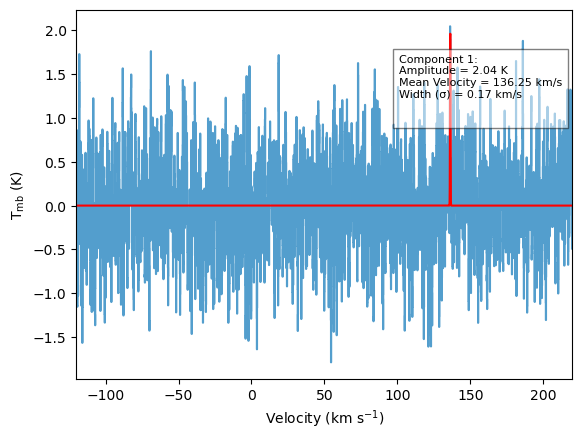

In [17]:
#object_name='12CO_HIGALBM266.9139-0.9986'
#file_path = '/Users/kyriakos.trakakis/Desktop/Temp/Exceptions/'+object_name+'.rtf'  # Path to your RTF file
#exc_1 = rtf_to_numpy(file_path, delimiter=',')  # Adjust delimiter if needed
#shape=np.size(exc_1)
#xaxis=np.linspace(-120, 120, shape)

# Write to a FITS file
spectra_file='/Users/kyriakos.trakakis/Desktop/Temp/12CO_HIGALBM254.7480-0.7909_spec.fits'
#write_array_to_fits(exc_1, hd, spectra_file)

plot_1d(spectra_file, vmin= -120, vmax = 220)

## Deprecated versions

In [13]:
def noise_calc_1d(y):

    fig, ax = plt.subplots()
    y=np.array(y)
    #y = y[~np.isnan(y)]
    print(np.shape(y), y)
    y_negative = y[np.where(y <  0)]
    y_new = np.concatenate((y_negative,-1*y_negative),axis=None)
    y_mean = np.nanmean(y_new)
    y_stdev = np.nanstd(y_new)

    y_noise_array =  y[np.where(y <  abs(y_stdev*5))]

    n, bin_edges, p = plt.hist(y_noise_array,bins = 20, alpha=0.5,color='rosybrown',align='mid' )

    gauss_bins = bin_edges[:-1]+((bin_edges[1]-bin_edges[0])/2.)

    #print(np.mean(y_noise_array), np.max(y_noise_array))
    popt, pcov = curve_fit(gaus,gauss_bins, n, p0=[np.nanmax(n),np.nanmean(y_noise_array),np.nanstd(y_noise_array)])
    #print(popt)

    guass_fit_bins = (np.array(range(-90,100,1))-5)/200.
    ax.plot(guass_fit_bins,gaus(guass_fit_bins,*popt),'r')
    plt.axvline(x=3*abs(popt[2]), color='grey', linestyle=':')
    ax.set_xlabel('T$_{mb}$ [K]')
    ax.set_ylabel('Number of Channels')
    noise_string = r'RMS Noise ($\sigma$)= '+str(round(abs(popt[2]),2)) + ' K'
    mean_string = r'Mean Offset= '+str(round(abs(popt[1]),2)) + ' K'
    plt.text(0.05, 0.9, noise_string, transform=ax.transAxes)
    plt.text(0.05, 0.8, mean_string, transform=ax.transAxes)

    y = [n-popt[1] for n in y]
    y_noise_array = [n-popt[1] for n in y_noise_array]
    n, bins, p = plt.hist(y_noise_array,bins=bin_edges, alpha=0.25,color='green',align='mid' )
    ###plt.savefig(output_dir+f'{file}_noise.png')
    #plt.show()    #<--------------------- make shure this is commented when running big loop
    plt.close()

    print('')
    print('-----Noise parameter is calculated -----')
    print('')

    return(1*abs(popt[2]), y)

In [14]:
def plot_spectra_1D(Tmb, xaxis, vmin=-120, vmax=120):
    # Smooth the data to reduce noise
    Tmb = smooth(Tmb, 5, 'hanning')
    fin=np.isfinite(Tmb)
    Tmb=Tmb[fin]

    # Noise calculation
    noise, y = noise_calc_1d(Tmb)
    y=np.array(y)
    y = y[~np.isnan(y)]
    # Find peaks

    
    # Set guesses based on component count
    width_guess = 0.5
    gauss_fn = None
    guesses = [7, 15, width_guess]
    gauss_fn = gaus
    

    # Fit the Gaussian model if appropriate
    if gauss_fn:
        try:
            weight = np.zeros_like(y) + noise
            popt, pcov = curve_fit(gauss_fn, xaxis, Tmb, guesses, sigma=weight, absolute_sigma=True)
            
            # Separate the parameters
            amplitudes = popt[0::3]
            mean_velocities = popt[1::3]
            widths = popt[2::3]

            # Plot the results
            fig, ax = plt.subplots()
            plt.step(xaxis, Tmb, color='#539ecd')
            plt.plot(xaxis, gauss_fn(xaxis, *popt), 'r')

            # Display Gaussian parameters on the plot
            param_str = ''
            for i in range(0, len(popt), 3):
                param_str += f'Component {i//3 + 1}:\n'
                param_str += f'Amplitude = {popt[i]:.2f} K\n'
                param_str += f'Mean Velocity = {popt[i+1]:.2f} km/s\n'
                param_str += f'Width (σ) = {popt[i+2]:.2f} km/s\n\n'

            plt.text(0.65, 0.7, param_str, transform=ax.transAxes, fontsize=8,
                     bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))

            ax.set_xlim([vmin, vmax])
            plt.ylabel(r'T$_{\rm mb}$ (K)')
            plt.xlabel(r'Velocity (km s$^{-1}$)')
            plt.title('12CO_HIGALBM259.9911-0.2148')
            plt.savefig('/Users/kyriakos.trakakis/Desktop/Temp/Exceptions/12CO_HIGALBM259.9911-0.2148.png')
            plt.show()
        except Exception as e:
            print(f"Failed to fit Gaussian: {e}")
    else:
        print("No suitable Gaussian components detected or too many components.")

In [15]:
plot_spectra_1D(exc_1,xaxis)

ValueError: object too deep for desired array

In [120]:
def plot_1d_old(spectra_file, vmin=-600, vmax=500):
    # Read the FITS file
    with fits.open(spectra_file) as hdul:
        Tmb = hdul[0].data
        hd = hdul[0].header

    # Extract necessary header values
    refc = hd['CRPIX3']
    velo = hd['CRVAL3']
    dv = hd['CDELT3']

    # Create the velocity axis
    Vlsr = (velo + (np.arange(1, hd['NAXIS1'] + 1) - refc) * dv) / 1000.0  # Convert to km/s
    xaxis = Vlsr

    # Trim data within the velocity range
    if vmin is not None and vmax is not None:
        valid_indices = (xaxis >= vmin) & (xaxis <= vmax)
        xaxis = xaxis[valid_indices]
        if Tmb.ndim==2:
            Tmb = Tmb[0,valid_indices]
        else:
            Tmb=Tmb[valid_indices]

    # Smooth the data to reduce noise
    Tmb = smooth(Tmb, 5, 'hanning')

    # Plot the spectrum
    fig, ax = plt.subplots(figsize=(20,5))
    plt.step(xaxis, Tmb, color='#539ecd')
    plt.ylabel(r'T$_{\rm mb}$ (K)')
    plt.xlabel(r'Velocity (km s$^{-1}$)')
    plt.title(f'{spectra_file[:-10]}')
    plt.xlim([vmin, vmax])

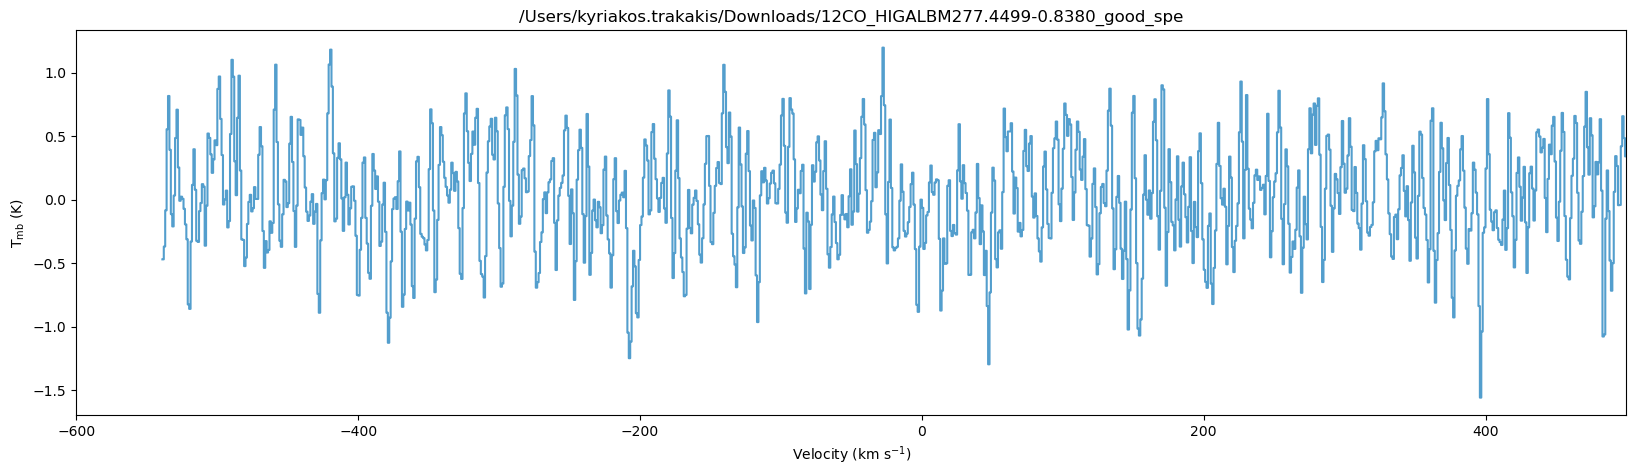

In [154]:
plot_1d_old('/Users/kyriakos.trakakis/Downloads/12CO_HIGALBM277.4499-0.8380_good_spectrum.fits')

In [97]:
with fits.open('/Users/kyriakos.trakakis/Downloads/MOPRA_HiGAL/12CO_HIGALBM277.4418-0.8661_gaia_spec.fits') as hdul:
    Tmb = hdul[0].data
    hd = hdul[0].header

refc = hd['CRPIX3']
velo = hd['CRVAL3']
dv = hd['CDELT3']

In [154]:
Tmb.min()

-0.9789072

In [149]:
Vlsr = (velo + (np.arange(1, hd['NAXIS1'] + 1) - refc) * dv) / 1000.0  # Convert to km/s

In [153]:
velo

-36.90479246648706

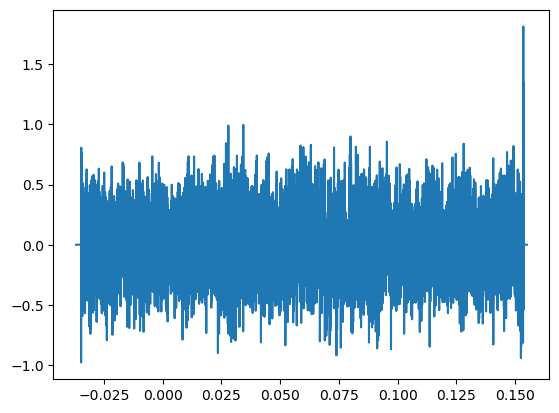

In [152]:
plt.plot(Vlsr, Tmb)

In [23]:
with fits.open(spectra_file) as hdul:
    Tmb = hdul[0].data
    hd = hdul[0].header

In [28]:
Tmb.ndim

2